# Trabalho 01 - Bancos de Dados para Ciencia de Dados

**Dengue nos municipios brasileiros: casos notificados, clima e porte populacional**

Gabriel Rodrigues da Silva - RA 800277

Este notebook cobre os itens (h) e (i) do enunciado: conexao com o MongoDB usando PyMongo e visualizacao dos dados recuperados das duas bases.

## Item (h) - Conexao com o MongoDB via PyMongo

In [1]:
# no Google Colab, descomente a linha abaixo antes de rodar
# !pip install pymongo

from pymongo import MongoClient

# mongod local na porta padrao, como nos slides da disciplina
cliente = MongoClient("mongodb://localhost:27017")

dengue = cliente["dengue_br"]
ibge = cliente["ibge"]

print("versao do servidor:", cliente.server_info()["version"])
for nome in ["dengue_br", "ibge"]:
    base = cliente[nome]
    for colecao in base.list_collection_names():
        print(f"  {nome}.{colecao}: {base[colecao].count_documents({})} documentos")

versao do servidor: 8.0.31
  dengue_br.alertas: 176098 documentos
  ibge.municipios: 5571 documentos
  ibge.populacao: 5571 documentos


## Item (i) - Visualizacao 1: Base 1 (dengue_br.alertas)

Sazonalidade da dengue: total de casos notificados por semana epidemiologica, somando os anos de 2015 a 2024 nos 338 municipios coletados.

semana de pico: 15
casos na semana de pico: 857581
total de casos no periodo: 16389422


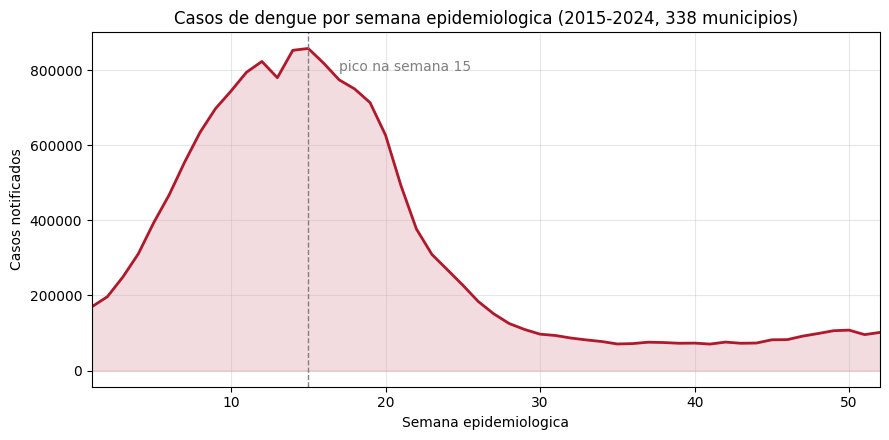

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
from pathlib import Path

PRINTS = Path("..") / "prints"
PRINTS.mkdir(exist_ok=True)

# o campo SE tem o formato AAAASS, entao o resto da divisao por 100 devolve a semana
pipeline_dengue = [
    {"$addFields": {"semana": {"$mod": ["$SE", 100]}}},
    {"$match": {"semana": {"$lte": 52}}},
    {"$group": {"_id": "$semana", "casos": {"$sum": {"$ifNull": ["$casos", 0]}}}},
    {"$sort": {"_id": 1}},
]
resultado = list(dengue.alertas.aggregate(pipeline_dengue))

semanas = []
casos = []
for linha in resultado:
    semanas.append(linha["_id"])
    casos.append(linha["casos"])

pico = semanas[casos.index(max(casos))]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(semanas, casos, color="#b2182b", linewidth=2)
ax.fill_between(semanas, casos, color="#b2182b", alpha=0.15)
ax.axvline(pico, color="gray", linestyle="--", linewidth=1)
ax.annotate(
    f"pico na semana {pico}",
    xy=(pico, max(casos)),
    xytext=(pico + 2, max(casos) * 0.93),
    color="gray",
)
ax.set_title("Casos de dengue por semana epidemiologica (2015-2024, 338 municipios)")
ax.set_xlabel("Semana epidemiologica")
ax.set_ylabel("Casos notificados")
ax.set_xlim(1, 52)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PRINTS / "viz1-dengue-sazonalidade.png", dpi=150)

print("semana de pico:", pico)
print("casos na semana de pico:", max(casos))
print("total de casos no periodo:", sum(casos))
plt.show()

## Item (i) - Visualizacao 2: Base 2 (ibge.municipios + ibge.populacao)

Distribuicao da populacao estimada e da quantidade de municipios entre as cinco regioes do pais.

populacao total do pais: 214.2 milhoes
municipios somados: 5571


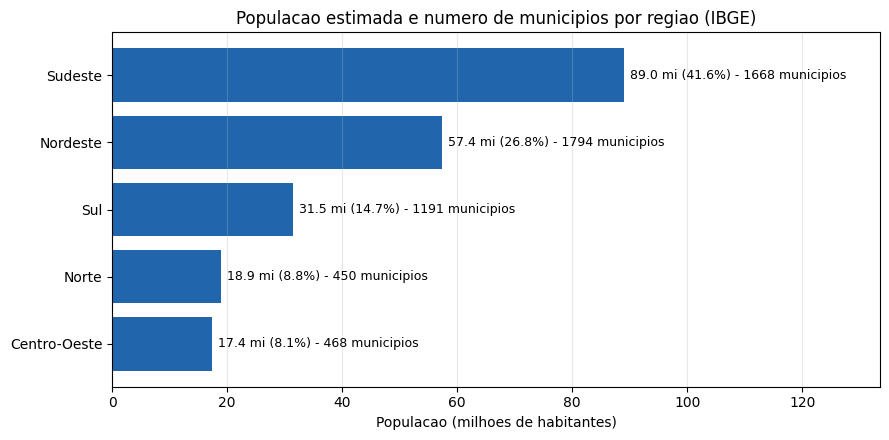

In [3]:
pipeline_ibge = [
    {
        "$lookup": {
            "from": "populacao",
            "localField": "id",
            "foreignField": "geocode",
            "as": "dados_populacao",
        }
    },
    {"$unwind": "$dados_populacao"},
    {
        "$group": {
            "_id": "$regiao-imediata.regiao-intermediaria.UF.regiao.nome",
            "populacao": {"$sum": "$dados_populacao.populacao"},
            "municipios": {"$sum": 1},
        }
    },
    {"$sort": {"populacao": -1}},
]
regioes = list(ibge.municipios.aggregate(pipeline_ibge))

nomes = [regiao["_id"] for regiao in regioes]
populacoes = [regiao["populacao"] / 1_000_000 for regiao in regioes]
quantidades = [regiao["municipios"] for regiao in regioes]
total = sum(populacoes)

fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.barh(nomes, populacoes, color="#2166ac")
ax.invert_yaxis()
for barra, populacao, quantidade in zip(barras, populacoes, quantidades):
    ax.text(
        populacao + 1,
        barra.get_y() + barra.get_height() / 2,
        f"{populacao:.1f} mi ({populacao / total * 100:.1f}%) - {quantidade} municipios",
        va="center",
        fontsize=9,
    )
ax.set_title("Populacao estimada e numero de municipios por regiao (IBGE)")
ax.set_xlabel("Populacao (milhoes de habitantes)")
ax.set_xlim(0, max(populacoes) * 1.5)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(PRINTS / "viz2-ibge-regioes.png", dpi=150)

print(f"populacao total do pais: {total:.1f} milhoes")
print("municipios somados:", sum(quantidades))
plt.show()